### Import Libraries

In [ ]:
import os
import ast
import json
import zipfile
from io import BytesIO
from matplotlib.patches import Rectangle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from huggingface_hub import hf_hub_download
from PIL import Image as PILImage

# Helper function to load images from Hugging Face dataset
def load_hf_image(image_path):
    relative_path = image_path.removeprefix("DGM4/")
    path_parts = relative_path.split("/")
    archive_name = "/".join(path_parts[:2]) + ".zip"
    target_name = "/".join(path_parts[1:])

    archive_path = hf_hub_download(
        repo_id="rshaojimmy/DGM4",
        filename=archive_name,
        repo_type="dataset",
    )

    with zipfile.ZipFile(archive_path) as archive:
        matches = [
            name for name in archive.namelist()
            if name.endswith(target_name)
        ]
        if not matches:
            raise FileNotFoundError(
                f"{target_name} was not found in {archive_name}"
            )
        image_bytes = archive.read(matches[0])

    return PILImage.open(BytesIO(image_bytes)).convert("RGB")

### Load Datasets

In [39]:
ds = load_dataset("rshaojimmy/DGM4")

ds

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'image', 'fake_cls', 'fake_text_pos', 'mtcnn_boxes', 'fake_image_box'],
        num_rows: 208184
    })
    validation: Dataset({
        features: ['id', 'text', 'image', 'fake_cls', 'fake_text_pos', 'mtcnn_boxes', 'fake_image_box'],
        num_rows: 22126
    })
    test: Dataset({
        features: ['id', 'text', 'image', 'fake_cls', 'fake_text_pos', 'mtcnn_boxes', 'fake_image_box'],
        num_rows: 50705
    })
})

In [3]:
train_df = ds["train"].to_pandas()
val_df = ds["validation"].to_pandas()
test_df = ds["test"].to_pandas()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (208184, 7)
Validation: (22126, 7)
Test: (50705, 7)


### Focusing on the train dataset

DGM4 Dataset Columns

- `id`: Identifies the news image-caption pair.
- `image`: The news image.
- `text`: The news caption associated with the image.
- `fake_cls`: Ground-truth manipulation class (e.g. original, image manipulation, text manipulation).
- `fake_image_box`: Bounding box indicating the manipulated region in the image.
- `fake_text_pos`: Positions of manipulated words/tokens in the caption.
- `mtcnn_boxes`: Bounding boxes of faces detected in the image using MTCNN.

> **Note:** `fake_cls`, `fake_image_box`, and `fake_text_pos` are ground-truth annotations and should not be used as model input features.

In [4]:
train_df.head()

,id,text,image,fake_cls,fake_text_pos,mtcnn_boxes,fake_image_box
0,995762,A Victorian court decided on Friday that forme...,DGM4/manipulation/infoswap/995762-043201-infos...,face_swap,[],"[[178, 35, 226, 99], [357, 39, 401, 95], [58, ...","[178, 35, 226, 99]"
1,69406,What s the biggest surprise from the JPMorgan ...,DGM4/manipulation/simswap/69406-106968-simswap...,face_swap,[],"[[159, 18, 208, 79], [259, 44, 280, 70]]","[159, 18, 208, 79]"
2,1486322,Chanan Reitblat told the court said felt viola...,DGM4/manipulation/simswap/1486322-004604-simsw...,face_swap,[],"[[185, 51, 328, 237], [388, 118, 464, 229], [7...","[388, 118, 464, 229]"
3,45310,David Oyelowo left and Michael Keaton,DGM4/origin/washington_post/0065/855.jpg,orig,[],"[[151, 34, 184, 78], [204, 35, 234, 77]]",[]
4,335277,Connecticut Governor Dannel P Malloy and First...,DGM4/manipulation/infoswap/335277-177841-infos...,face_swap,[],"[[122, 62, 161, 126], [169, 74, 209, 124], [32...","[321, 94, 357, 148]"


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 208184 entries, 0 to 208183
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   id              208184 non-null  int64 
 1   text            208184 non-null  str   
 2   image           208184 non-null  str   
 3   fake_cls        208184 non-null  str   
 4   fake_text_pos   208184 non-null  object
 5   mtcnn_boxes     208184 non-null  object
 6   fake_image_box  208184 non-null  object
dtypes: int64(1), object(3), str(3)
memory usage: 40.5+ MB


In [7]:
# No missing values in the train dataset
missing = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_percentage": train_df.isna().mean() * 100
})

missing.sort_values("missing_percentage", ascending=False)

,missing_count,missing_percentage
id,0,0.0
text,0,0.0
image,0,0.0
fake_cls,0,0.0
fake_text_pos,0,0.0
mtcnn_boxes,0,0.0
fake_image_box,0,0.0


### Explore IDs

In [17]:
id_counts = train_df["id"].value_counts()

id_counts.head(10)

id
1183390    7
319730     7
918531     7
1206145    7
1031116    7
356576     7
1612517    7
964436     7
320319     7
1493070    7
Name: count, dtype: int64

In [14]:
print("Unique IDs:", train_df["id"].nunique())
print("Total rows:", len(train_df))
print("Rows belonging to duplicated IDs:", (id_counts > 1).sum())

Unique IDs: 56894
Total rows: 208184
Rows belonging to duplicated IDs: 52648


In [ ]:
duplicated_ids = id_counts[id_counts > 1].index

train_df[
    train_df["id"].isin(duplicated_ids)
].sort_values("id").head(8)

# There are duplicates of the orig which we need to clean up.
# what is the point of the unique IDs though, only have orig then no manipulations.

,id,text,image,fake_cls,fake_text_pos,mtcnn_boxes,fake_image_box
180976,39153,US first lady Michelle Obama enters the East R...,DGM4/manipulation/infoswap/39153-187724-infosw...,face_swap,[],"[[152, 50, 183, 92], [89, 91, 105, 113]]","[152, 50, 183, 92]"
137091,39153,Michelle Obama Rigged election warnings are tr...,DGM4/origin/washington_post/0510/613.jpg,text_swap,"[2, 3, 4, 5, 6, 7, 8, 10, 11]","[[152, 50, 183, 92], [89, 91, 105, 113]]",[]
78923,39153,US first lady Michelle Obama enters the East R...,DGM4/origin/washington_post/0510/613.jpg,orig,[],"[[152, 50, 183, 92], [89, 91, 105, 113]]",[]
66674,39153,US first lady Michelle Obama enters the East R...,DGM4/manipulation/StyleCLIP/39153-StyleCLIP.jpg,face_attribute,[],"[[152, 50, 183, 92], [89, 91, 105, 113]]","[152, 50, 183, 92]"
21418,39153,US first lady Michelle Obama enters the East R...,DGM4/origin/washington_post/0510/613.jpg,orig,[],"[[152, 50, 183, 92], [89, 91, 105, 113]]",[]
140250,39189,Top US general says troops could be redeployed...,DGM4/origin/washington_post/0423/707.jpg,orig,[],"[[72, 98, 106, 145], [361, 104, 393, 146], [18...",[]
60400,39189,Top US general says troops could be redeployed...,DGM4/manipulation/infoswap/39189-035594-infosw...,face_swap,[],"[[72, 98, 106, 145], [361, 104, 393, 146], [18...","[154, 151, 166, 166]"
74346,39189,Top US general says troops could be redeployed...,DGM4/manipulation/StyleCLIP/39189-StyleCLIP.jpg,face_attribute,[],"[[72, 98, 106, 145], [361, 104, 393, 146], [18...","[361, 104, 393, 146]"


### Explore text

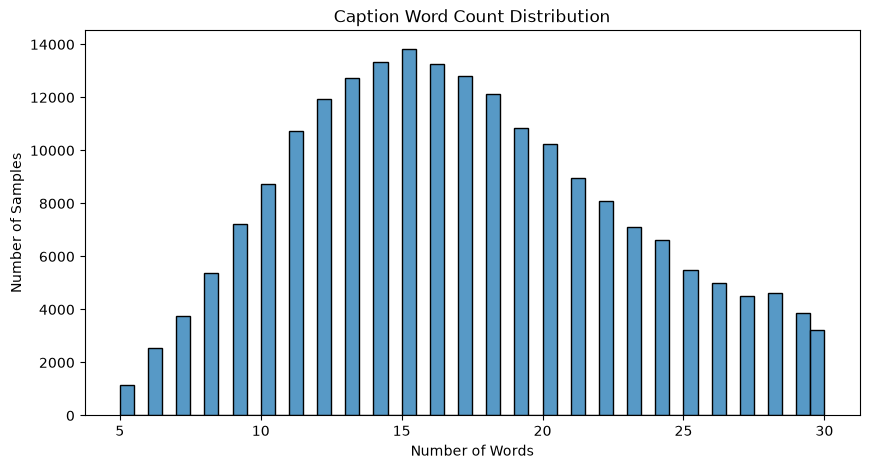

In [23]:
train_df["text_length"] = train_df["text"].fillna("").astype(str).str.len()

train_df["text_word_count"] = (
    train_df["text"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)


plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["text_word_count"],
    bins=50
)

plt.title("Caption Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Samples")

plt.show()

### Explore image

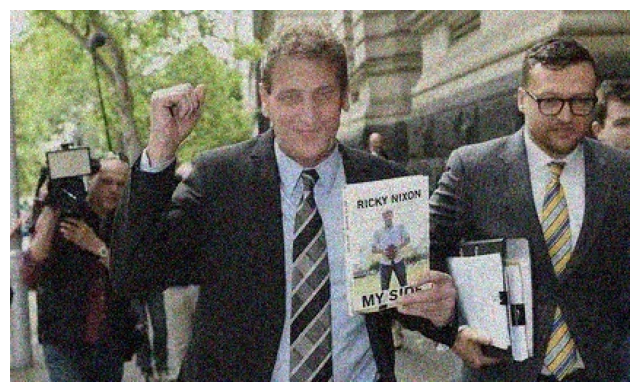

PIL.Image.Image

In [45]:
sample_image_path = ds["train"][0]["image"]
sample_image = load_hf_image(sample_image_path)

plt.figure(figsize=(8, 6))
plt.imshow(sample_image)
plt.axis("off")
plt.show()

type(sample_image)

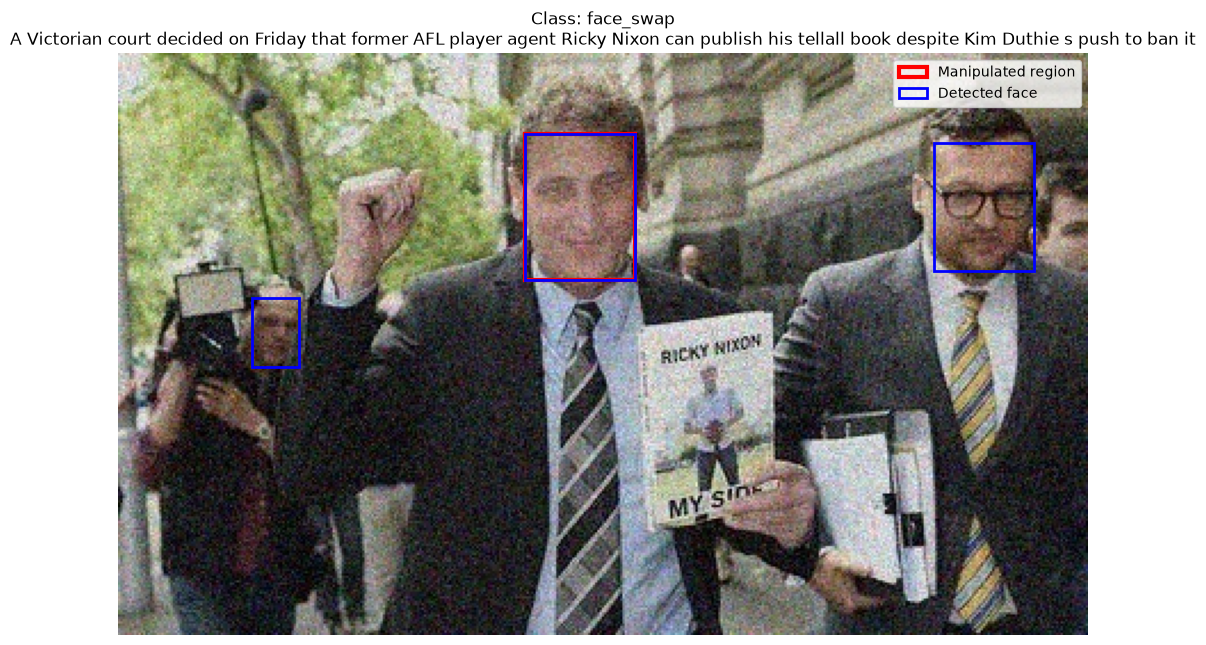

In [ ]:
# Check if the bounding boxes are correctly formatted and can be drawn on the images
def draw_box(ax, box, color, label=None, linewidth=2):
    if box is None or len(box) != 4:
        return

    x1, y1, x2, y2 = map(float, box)
    rectangle = Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor=color,
        linewidth=linewidth,
        label=label,
    )
    ax.add_patch(rectangle)


def plot_image_annotations(row):
    image = load_hf_image(row["image"])

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(image)

    fake_image_box = row["fake_image_box"]
    if fake_image_box is not None and len(fake_image_box) == 4:
        draw_box(
            ax,
            fake_image_box,
            color="red",
            label="Manipulated region",
            linewidth=3,
        )

    mtcnn_boxes = row["mtcnn_boxes"]
    if mtcnn_boxes is not None:
        for index, face_box in enumerate(mtcnn_boxes):
            draw_box(
                ax,
                face_box,
                color="blue",
                label="Detected face" if index == 0 else None,
            )

    ax.set_title(f"Class: {row['fake_cls']}\n{row['text']}")
    ax.axis("off")
    ax.legend()
    plt.tight_layout()
    plt.show()


example_row = train_df.iloc[0]
plot_image_annotations(example_row)

### Explore fake_cls
#### Facial Manipulations (Image Only)
* **`face_swap`**: The face of a person in the original image has been digitally replaced with someone else's face (a classic deepfake).
  * *Example:* A news photo of a politician where their face is seamlessly replaced with a celebrity's face, while the body and background remain untouched.
* **`face_attribute`**: The original person's face remains, but specific attributes—such as age, gender, expression, hair color, or skin tone—have been digitally modified.
  * *Example:* Changing a person's neutral expression to an angry scowl, or adding wrinkles to make them look significantly older.

#### Text Manipulations (Text Only)
* **`text_swap`**: Real text or names within the news headline/caption have been entirely swapped out for different words to completely change the meaning or context of the story.
  * *Original:* "Elon Musk announces new Tesla factory opening in Germany."
  * *Manipulated:* "Tim Cook announces new Tesla factory opening in Germany."
* **`text_attribute`**: The wording is mostly kept, but specific attributes or modifiers within the text (like numbers, dates, locations, or emotional tones) have been subtly altered to misinform.
  * *Original:* "Stocks rally by 5% after the economic report."
  * *Manipulated:* "Stocks crash by 15% after the economic report."

In [11]:
train_df["fake_cls"].value_counts(dropna=False)

fake_cls
orig                             104092
face_swap                         33704
face_attribute                    28513
text_swap                         13788
face_swap&text_swap                8317
face_attribute&text_swap           7004
text_attribute                     6009
face_swap&text_attribute           3649
face_attribute&text_attribute      3108
Name: count, dtype: int64

In [12]:
fake_cls_distribution = (
    train_df["fake_cls"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

fake_cls_distribution

fake_cls
orig                             50.00
face_swap                        16.19
face_attribute                   13.70
text_swap                         6.62
face_swap&text_swap               4.00
face_attribute&text_swap          3.36
text_attribute                    2.89
face_swap&text_attribute          1.75
face_attribute&text_attribute     1.49
Name: proportion, dtype: float64

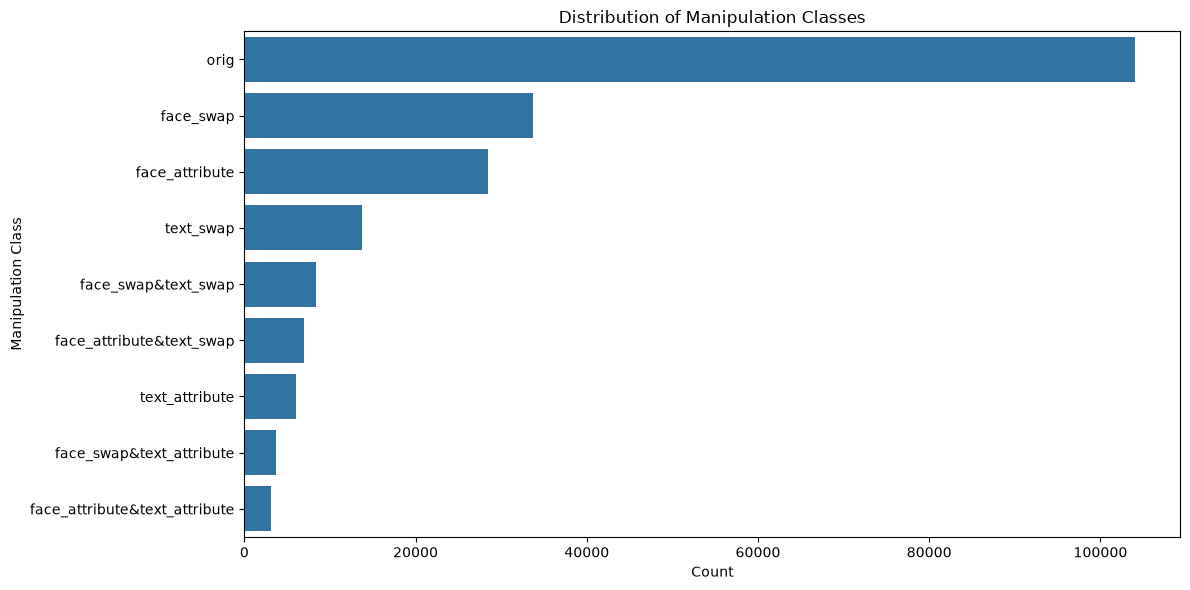

In [10]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=train_df,
    y="fake_cls",
    order=train_df["fake_cls"].value_counts().index
)

plt.title("Distribution of Manipulation Classes")
plt.xlabel("Count")
plt.ylabel("Manipulation Class")
plt.tight_layout()

plt.show()

### Explore fake_text_pos

In [18]:
train_df["fake_text_pos"].head(10)

0                                  []
1                                  []
2                                  []
3                                  []
4                                  []
5                                  []
6                                  []
7                                  []
8                                  []
9    [0, 5, 7, 8, 10, 11, 12, 13, 14]
Name: fake_text_pos, dtype: object

In [19]:
train_df["fake_text_pos"].apply(type).value_counts()

fake_text_pos
<class 'numpy.ndarray'>    208184
Name: count, dtype: int64

### Explore fake_image_box

In [20]:
train_df["fake_image_box"].head(10)

0      [178, 35, 226, 99]
1      [159, 18, 208, 79]
2    [388, 118, 464, 229]
3                      []
4     [321, 94, 357, 148]
5                      []
6     [283, 56, 424, 222]
7                      []
8                      []
9     [107, 57, 195, 191]
Name: fake_image_box, dtype: object

In [ ]:
train_df["fake_image_box"].apply(type).value_counts()

### Explore mtcnn_boxes

In [21]:
train_df["mtcnn_boxes"].head(10)

0    [[178, 35, 226, 99], [357, 39, 401, 95], [58, ...
1             [[159, 18, 208, 79], [259, 44, 280, 70]]
2    [[185, 51, 328, 237], [388, 118, 464, 229], [7...
3             [[151, 34, 184, 78], [204, 35, 234, 77]]
4    [[122, 62, 161, 126], [169, 74, 209, 124], [32...
5            [[93, 46, 190, 165], [148, 48, 229, 152]]
6          [[283, 56, 424, 222], [196, 183, 269, 274]]
7    [[301, 44, 378, 145], [14, 54, 86, 152], [180,...
8           [[105, 105, 172, 203], [265, 16, 327, 95]]
9           [[107, 57, 195, 191], [354, 48, 424, 147]]
Name: mtcnn_boxes, dtype: object

### Looking across Train, Validation and Test

In [ ]:
# Check if the ids are unique across train, validation, and test sets
train_ids = set(train_df["id"])
val_ids = set(val_df["id"])
test_ids = set(test_df["id"])

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


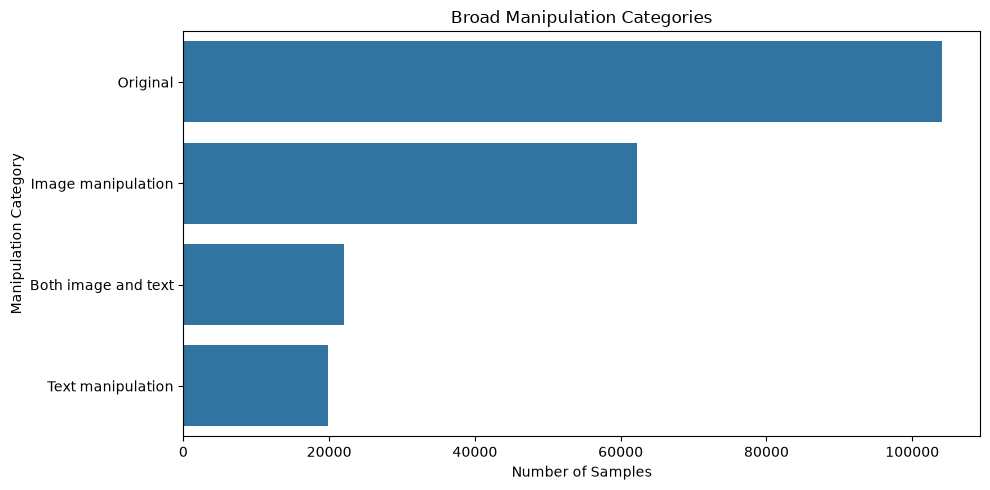

,train,validation,test
manipulation_group,,,
Original,50.00,33.77,33.28
Image manipulation,29.89,39.71,38.33
Both image and text,10.61,14.22,14.73
Text manipulation,9.51,12.29,13.66


In [ ]:
# Look at broad manipulation categories
def get_manipulation_group(label):
    label = str(label).lower()

    if label in {"orig", "original", "real"}:
        return "Original"

    has_image_manipulation = "face" in label or "image" in label
    has_text_manipulation = "text" in label

    if has_image_manipulation and has_text_manipulation:
        return "Both image and text"
    if has_image_manipulation:
        return "Image manipulation"
    if has_text_manipulation:
        return "Text manipulation"

    return "Other"


for df in (train_df, val_df, test_df):
    df["manipulation_group"] = df["fake_cls"].apply(
        get_manipulation_group
    )

manipulation_counts = train_df["manipulation_group"].value_counts()

plt.figure(figsize=(10, 5))
sns.countplot(
    data=train_df,
    y="manipulation_group",
    order=manipulation_counts.index,
)
plt.title("Broad Manipulation Categories")
plt.xlabel("Number of Samples")
plt.ylabel("Manipulation Category")
plt.tight_layout()
plt.show()

manipulation_distribution = pd.concat(
    {
        split: df["manipulation_group"].value_counts(normalize=True)
        for split, df in split_dfs.items()
    },
    axis=1,
).fillna(0)

(manipulation_distribution * 100).round(2)

In [53]:
split_dfs = {
    "train": train_df,
    "validation": val_df,
    "test": test_df,
}

split_summary = pd.DataFrame({
    split: {
        "rows": len(df),
        "unique_ids": df["id"].nunique(),
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_scalar_rows": int(
            df.duplicated(
                subset=["id", "text", "fake_cls"]
            ).sum()
        ),
    }
    for split, df in split_dfs.items()
}).T

split_summary

split_class_distribution = pd.concat(
    {
        split: df["fake_cls"].value_counts(normalize=True)
        for split, df in split_dfs.items()
    },
    axis=1,
).fillna(0)

(split_class_distribution * 100).round(2)

,train,validation,test
fake_cls,,,
orig,50.00,33.77,33.28
face_swap,16.19,21.64,20.74
face_attribute,13.70,18.07,17.59
text_swap,6.62,8.56,9.77
face_swap&text_swap,4.00,5.26,5.79
face_attribute&text_swap,3.36,4.36,4.99
text_attribute,2.89,3.73,3.89
face_swap&text_attribute,1.75,2.41,2.20
face_attribute&text_attribute,1.49,2.20,1.75
